# Proyecto de flujo de datos — Bicis compartidas de Toulouse (estación *pomme*)

**Notebook 2: estrategia de modelado y evaluación (sección 4) y aplicación de técnicas (secciones 5.1 a 5.4).**

Recordatorio del objetivo: un sistema de alerta que, **cada 30 minutos**, prediga si **dentro de 2 horas** la estación *pomme* tendrá **2 bicis o menos**, y que detecte cuándo cambia el patrón de uso (*data drift*) y cuándo el modelo deja de ser fiable (*concept drift*).

**Requisito:** el fichero `flujo_pomme_30min.csv` generado por el notebook 1, en la misma carpeta que este notebook.

Hipótesis del exploratorio (notebook 1, sección 3.7):

| | Hipótesis | Se comprueba en |
|---|---|---|
| **H1** | *Data drift* en el uso de la estación con las vacaciones de verano y la vuelta a clase | 5.3 y 5.4 |
| **H2** | *Concept drift* en septiembre: cambia la probabilidad de quedarse sin bicis | 5.2 |
| **H3** | El ciclo diario y semanal es un drift recurrente que no debería disparar alarmas | 5.3 |
| **H4** | La bajada de temperatura de mediados de septiembre es *data drift* que no afecta al modelo | 5.3 |

## 0. Instalación, imports y lectura del flujo

In [23]:
import importlib.metadata as metadata
import os
import sys

numpy_antes = metadata.version("numpy")
%pip install -q river
if "google.colab" in sys.modules and metadata.version("numpy") != numpy_antes:
    print("Reiniciando la sesión... después ejecutad desde la celda de los imports")
    os.kill(os.getpid(), 9)
else:
    print("River instalado")

Note: you may need to restart the kernel to use updated packages.
River instalado



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import collections
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import river
from river import drift, forest, linear_model, metrics, naive_bayes, preprocessing, stats, stream, tree

warnings.filterwarnings("ignore")
print("River:", river.__version__)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_rows", 100)

AZUL, NARANJA, VERDE, GRIS, SOMBRA, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985", "#e6e5e0", "#2b2b2a"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": SOMBRA, "grid.linewidth": 0.6,
    "axes.edgecolor": GRIS, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 9.5,
})

River: 0.26.1


El flujo se lee con `river.stream.iter_csv`, igual que en el notebook 1. `DELAY` es la espera entre instancias para simular la llegada en tiempo real; aquí vale 0 porque el flujo se recorre muchas veces (una por modelo y experimento). Con `DELAY = 0.01` cada recorrido tardaría ~1 minuto.

In [25]:
CSV_FLUJO = "flujo_pomme_30min.csv"
HORIZONTE = pd.Timedelta("2h")      # la etiqueta de t se conoce en t + 2 h
UMBRAL_POCAS = 2
DELAY = 0

COLUMNAS_X = ["bicis", "tendencia_1h", "hora", "dia_semana", "es_finde", "es_festivo",
              "temperatura", "humedad", "viento", "nubes", "llueve", "movimientos_30min"]


def a_numero(v):
    return float(v) if v != "" else None

CONVERTIDORES = {c: a_numero for c in COLUMNAS_X}
CONVERTIDORES["pocas_bicis_2h"] = lambda v: float(v) == 1


def flujo_bicis(ruta=CSV_FLUJO, delay=DELAY):
    """Una instancia cada 30 minutos (simulada con `delay` segundos). x["momento"] es solo para registro."""
    lector = stream.iter_csv(ruta, target="pocas_bicis_2h", converters=CONVERTIDORES,
                             parse_dates={"momento": "%Y-%m-%d %H:%M:%S"}, drop=["bicis_2h"])
    for x, y in lector:
        yield {k: v for k, v in x.items() if v is not None}, y
        if delay:
            time.sleep(delay)


x, y = next(flujo_bicis())
print(x, "->", y)

{'momento': datetime.datetime(2016, 6, 1, 0, 30), 'bicis': 3.0, 'hora': 0.5, 'dia_semana': 2.0, 'es_finde': 0.0, 'es_festivo': 0.0, 'temperatura': 17.36, 'humedad': 77.0, 'viento': 9.8, 'nubes': 90.0, 'llueve': 0.0, 'movimientos_30min': 2.0} -> True


# 4. Estrategia de modelado y evaluación

## 4.1 Evaluación *prequential* con retraso de la etiqueta

En un flujo de datos no hay partición train/test: el modelo **predice cada instancia antes de aprender de ella** (*test-then-train* o evaluación *prequential*), como en los notebooks del tema (`predict_one` → `learn_one` → `detector.update`).

Pero en nuestro problema hay un detalle importante: **la etiqueta llega 2 horas tarde**. A las 10:00 el sistema predice si a las 12:00 habrá 2 bicis o menos, y solo a las 12:00 sabe si ha acertado. Si aprendiéramos de la etiqueta en el mismo instante en que predecimos, estaríamos usando información del futuro y los resultados serían optimistas.

Por eso el bucle de evaluación funciona así cada vez que llega una instancia *x(t)*:
1. **Llegan las etiquetas** de las predicciones hechas hace 2 horas (o más): se comprueba si se acertó, se actualizan las métricas y **los detectores de drift**, y el modelo aprende de esas instancias.
2. **Se predice** *x(t)* y la predicción queda pendiente hasta *t* + 2 h.

Las detecciones de drift se fechan en el momento en que el sistema puede verlas (cuando llega la etiqueta), no en el de la predicción.

In [26]:
def variables_modelo(x):
    """Variables que recibe el modelo: todas menos el momento, más la hora en forma cíclica (23:30 está cerca de 0:00)."""
    xm = {k: v for k, v in x.items() if k != "momento"}
    xm["hora_sin"] = math.sin(2 * math.pi * x["hora"] / 24)
    xm["hora_cos"] = math.cos(2 * math.pi * x["hora"] / 24)
    return xm


def prequential(modelo, instancias, retraso=HORIZONTE, detectores=None, congelar_desde=None):
    """Evaluación test-then-train con la etiqueta retrasada `retraso`.
    detectores: dict nombre -> detector de River, que recibe el bit de error (1 = fallo).
    congelar_desde: a partir de esa fecha el modelo deja de aprender (para el experimento de la sección 5.2).
    Devuelve (registro por instancia, fechas de detección por detector)."""
    retraso = pd.Timedelta(retraso)
    detectores = detectores or {}
    pendientes = collections.deque()
    registros, detecciones = [], {nombre: [] for nombre in detectores}
    for x, y in instancias:
        t = x["momento"]
        # 1) Llegan las etiquetas de las predicciones hechas hace `retraso`
        while pendientes and pendientes[0][0] + retraso <= t:
            t0, x0, y0, p0 = pendientes.popleft()
            error = int(p0 != y0)
            registros.append((t0, t, y0, p0, error))
            for nombre, det in detectores.items():
                det.update(error)
                if det.drift_detected:
                    detecciones[nombre].append(t)
            if congelar_desde is None or t < congelar_desde:
                modelo.learn_one(x0, y0)
        # 2) Llega x(t): se predice y queda pendiente
        xm = variables_modelo(x)
        p = modelo.predict_one(xm)
        pendientes.append((t, xm, y, bool(p) if p is not None else False))
    registro = pd.DataFrame(registros, columns=["momento", "revelada", "y", "y_pred", "error"]).set_index("momento")
    return registro, detecciones


def resumen(registro):
    acc, f1 = metrics.Accuracy(), metrics.F1()
    for y, p in zip(registro["y"], registro["y_pred"]):
        acc.update(y, p)
        f1.update(y, p)
    return {"accuracy_%": round(100 * acc.get(), 1), "F1_alerta_%": round(100 * f1.get(), 1)}

## 4.2 *Baselines*

Un modelo solo tiene sentido si mejora lo que se consigue sin aprender nada:
- **Clase mayoritaria:** predice siempre la clase más frecuente vista hasta el momento.
- **Persistencia:** "si ahora hay 2 bicis o menos, dentro de 2 horas también". Es el *baseline* natural en series temporales y aquí es muy exigente, porque el estado de la estación cambia despacio.

In [27]:
class ClaseMayoritaria:
    def __init__(self):
        self.conteo = collections.Counter()
    def predict_one(self, x):
        return self.conteo.most_common(1)[0][0] if self.conteo else False
    def learn_one(self, x, y):
        self.conteo[y] += 1


class Persistencia:
    def predict_one(self, x):
        return x["bicis"] <= UMBRAL_POCAS
    def learn_one(self, x, y):
        pass

## 4.3 ¿Por qué un horizonte de 2 horas?

Comparamos la persistencia con un modelo online (`ARFClassifier`, ver 5.1) para distintos horizontes de predicción. Las etiquetas de cada horizonte se calculan a partir de la columna `bicis` del flujo, y en cada caso la etiqueta llega con el retraso de su horizonte.

In [28]:
base = pd.read_csv(CSV_FLUJO, parse_dates=["momento"]).set_index("momento")


def instancias_con_horizonte(horizonte):
    futuro = base["bicis"].reindex(base.index + pd.Timedelta(horizonte)).to_numpy()
    tabla = base.assign(y=futuro <= UMBRAL_POCAS)[~np.isnan(futuro)]
    for t, fila in tabla.iterrows():
        x = {k: fila[k] for k in COLUMNAS_X if pd.notna(fila[k])}
        x["momento"] = t
        yield x, bool(fila["y"])


filas = []
for h in ["30min", "1h", "2h", "3h"]:
    fila = {"horizonte": h}
    for nombre, fab in {"Persistencia": Persistencia,
                        "ARF": lambda: forest.ARFClassifier(n_models=10, seed=42)}.items():
        registro, _ = prequential(fab(), instancias_con_horizonte(h), retraso=h)
        fila[f"{nombre} accuracy_%"] = resumen(registro)["accuracy_%"]
    fila["mejora ARF (puntos)"] = round(fila["ARF accuracy_%"] - fila["Persistencia accuracy_%"], 1)
    filas.append(fila)
pd.DataFrame(filas).set_index("horizonte")

,Persistencia accuracy_%,ARF accuracy_%,mejora ARF (puntos)
horizonte,,,
30min,88.6,88.2,-0.4
1h,83.1,85.3,2.2
2h,75.3,82.3,7.0
3h,69.4,81.2,11.8


**Conclusión.** A 30 minutos el modelo no supera a la persistencia (−0,5 puntos): el estado actual casi determina el futuro y no hay nada que aprender. Al alargar el horizonte, la persistencia pierde fuerza (del 88,6 % al 69,4 %) y el modelo aporta cada vez más: +7 puntos a 2 horas y +11,4 a 3 horas.

Elegimos **2 horas**: el modelo aporta claramente y es un margen útil para avisar a los usuarios o reponer bicis. A 3 horas el modelo aportaría más, pero la etiqueta tardaría más en llegar y el sistema reaccionaría más tarde a los cambios.

## 4.4 Efecto del retraso de la etiqueta

Mismo modelo y mismo horizonte (2 h), evaluado de dos formas: aprendiendo de la etiqueta en el mismo instante en que predice (**incorrecto**: usa el futuro) y aprendiendo cuando la etiqueta llega de verdad, 2 horas después.

In [29]:
filas = {}
for nombre, retraso in [("Sin retraso (optimista, incorrecto)", "0min"), ("Retraso de 2 h (realista)", "2h")]:
    registro, _ = prequential(forest.ARFClassifier(n_models=10, seed=42), flujo_bicis(), retraso=retraso)
    filas[nombre] = resumen(registro)
pd.DataFrame(filas).T

,accuracy_%,F1_alerta_%
"Sin retraso (optimista, incorrecto)",84.0,81.0
Retraso de 2 h (realista),82.1,78.6


**Conclusión.** Ignorar el retraso infla la accuracy en 1,8 puntos (84,4 % frente a 82,6 %) y el F1 en 2,2. Todos los resultados que siguen usan el retraso realista de 2 horas.

El retraso también afecta a los detectores de *concept drift*: como el error se conoce 2 horas tarde, **cualquier detección llega como mínimo 2 horas después del cambio**.

## 4.5 Métricas y evaluación de los detectores

**Métricas del modelo:**
- **Accuracy** prequential: % de aciertos.
- **F1 de la clase alerta**: la alerta es la clase que interesa y está algo desequilibrada (43 %).
- **Accuracy semanal**: para ver la evolución en el tiempo y si el modelo se degrada.

**¿Cómo se evalúa un detector de drift si no sabemos dónde está el drift real?** En los notebooks del tema se usan flujos sintéticos con el cambio en una posición conocida. En un flujo real no existe esa verdad, así que:
1. Se comparan las detecciones con **eventos conocidos** del calendario de Toulouse en 2016: inicio de las vacaciones escolares de verano (**6 de julio**), festivos (**14 de julio** y **15 de agosto**), vuelta a clase en los colegios (**1 de septiembre**) y en la universidad (mediados de septiembre), y la bajada de temperatura del **14 de septiembre** (notebook 1).
2. Se cuentan las **alarmas por mes**: un detector que salta continuamente no sirve para tomar decisiones.
3. Se comprueba si una alarma de *concept drift* va acompañada de una **subida real del error** (si el error no sube, es una falsa alarma).
4. Se ignoran las detecciones de las **2 primeras semanas**, mientras el modelo aún está aprendiendo y su error baja.

In [30]:
INICIO_EVALUACION = pd.Timestamp("2016-06-15")     # 2 semanas de aprendizaje inicial
VACACIONES = (pd.Timestamp("2016-07-06"), pd.Timestamp("2016-08-31"))
EVENTOS = {"6 jul: vacaciones": "2016-07-06", "14 jul: festivo": "2016-07-14", "15 ago: festivo": "2016-08-15",
           "1 sep: vuelta a clase": "2016-09-01", "14 sep: baja la temperatura": "2016-09-14"}
EVENTOS = {k: pd.Timestamp(v) for k, v in EVENTOS.items()}


def dibujar_detecciones(senal, detecciones, titulo, ylabel, desde=None):
    """Arriba la señal vigilada; abajo una fila por detector con sus detecciones ( | )."""
    nombres = list(detecciones)
    fig, (a1, a2) = plt.subplots(2, 1, sharex=True, figsize=(11, 2.8 + 0.32 * len(nombres)),
                                 gridspec_kw={"height_ratios": [2.4, 0.32 * len(nombres) + 0.3], "hspace": 0.08})
    a1.plot(senal.index, senal.values, color=AZUL, lw=1.4)
    for ax in (a1, a2):
        ax.axvspan(*VACACIONES, color=SOMBRA, lw=0, zorder=0)
        for nombre, fecha in EVENTOS.items():
            ax.axvline(fecha, color=GRIS, ls=":", lw=1)
        if desde is not None:
            ax.axvspan(senal.index.min(), desde, color="#f4f3ef", lw=0, zorder=0)
    a1.text(VACACIONES[0] + pd.Timedelta(days=1), a1.get_ylim()[1], "vacaciones escolares", va="top", color=TINTA, fontsize=8.5)
    for j, nombre in enumerate(nombres):
        fechas = [d for d in detecciones[nombre] if desde is None or d >= desde]
        a2.scatter(fechas, [j] * len(fechas), marker="|", s=180, lw=2, color=TINTA)
    a2.set_yticks(range(len(nombres)))
    a2.set_yticklabels([f"{n} ({len([d for d in detecciones[n] if desde is None or d >= desde])})" for n in nombres])
    a2.set_ylim(len(nombres) - 0.5, -0.5)
    a2.grid(axis="y", visible=False)
    a1.set_title(titulo)
    a1.set_ylabel(ylabel)
    plt.show()

# 5. Aplicación de técnicas

## 5.1 Modelos online

Todos los modelos de River que aprenden instancia a instancia:

| Modelo | Tipo | Por qué probarlo |
|---|---|---|
| `HoeffdingTreeClassifier` | árbol de decisión incremental | el modelo de los notebooks del tema |
| `HoeffdingAdaptiveTreeClassifier` | árbol con ADWIN en cada nodo | se adapta solo al drift sustituyendo ramas |
| `ARFClassifier` (10 árboles) | *Adaptive Random Forest* | ensemble con un detector de drift por árbol |
| `StandardScaler` + `LogisticRegression` | lineal | modelo simple de referencia (necesita escalar) |
| `GaussianNB` | Naive Bayes | muy rápido, supone variables independientes |

In [31]:
MODELOS = {
    "Clase mayoritaria": ClaseMayoritaria,
    "Persistencia": Persistencia,
    "Hoeffding Tree": lambda: tree.HoeffdingTreeClassifier(),
    "Hoeffding Adaptive Tree": lambda: tree.HoeffdingAdaptiveTreeClassifier(seed=42),
    "ARF (10 árboles)": lambda: forest.ARFClassifier(n_models=10, seed=42),
    "Regresión logística": lambda: preprocessing.StandardScaler() | linear_model.LogisticRegression(),
    "Gaussian Naive Bayes": lambda: naive_bayes.GaussianNB(),
}

registros, filas = {}, {}
for nombre, fab in MODELOS.items():
    t0 = time.time()
    registros[nombre], _ = prequential(fab(), flujo_bicis())
    r = registros[nombre]
    filas[nombre] = {**resumen(r),
                     **{f"acc_{m}": round(100 * (1 - e.mean()), 1)
                        for m, e in r["error"].groupby(r.index.month)},
                     "segundos": round(time.time() - t0, 1)}
tabla_modelos = pd.DataFrame(filas).T
tabla_modelos.columns = [c.replace("acc_6", "jun").replace("acc_7", "jul").replace("acc_8", "ago")
                         .replace("acc_9", "sep").replace("acc_10", "oct") for c in tabla_modelos.columns]
tabla_modelos

,accuracy_%,F1_alerta_%,jun,jul,ago,sep,oct,segundos
Clase mayoritaria,56.0,13.2,50.1,60.1,64.1,50.1,49.8,0.1
Persistencia,75.3,71.3,75.7,73.5,75.6,75.8,80.1,0.1
Hoeffding Tree,80.3,75.0,78.7,78.6,82.5,80.4,86.1,0.3
Hoeffding Adaptive Tree,79.7,75.9,79.8,78.4,79.6,80.4,86.6,0.5
ARF (10 árboles),82.1,78.6,80.2,81.1,84.7,81.5,86.6,5.1
Regresión logística,80.0,77.2,78.3,78.2,80.5,82.8,81.6,0.2
Gaussian Naive Bayes,76.7,74.5,75.7,76.9,77.4,76.7,77.1,0.4


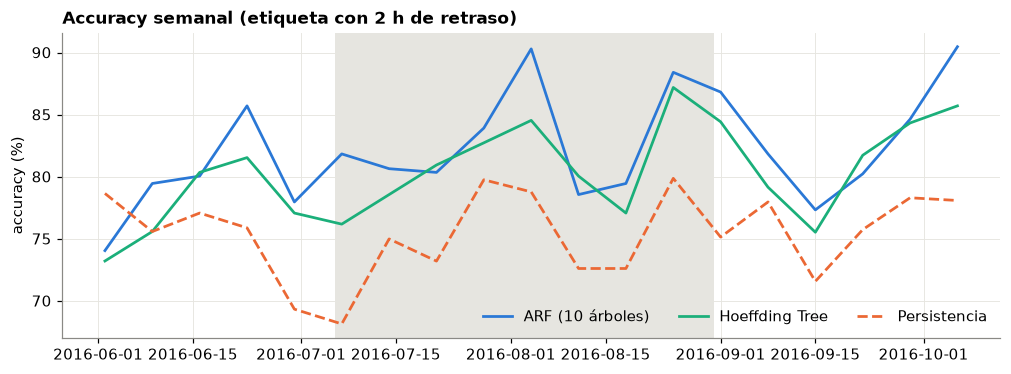

In [32]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for nombre, color, ls in [("ARF (10 árboles)", AZUL, "-"), ("Hoeffding Tree", VERDE, "-"), ("Persistencia", NARANJA, "--")]:
    acc_sem = 100 * (1 - registros[nombre]["error"].resample("W-SUN").mean())
    acc_sem.index = acc_sem.index - pd.Timedelta(days=3)
    ax.plot(acc_sem.index, acc_sem.values, color=color, ls=ls, lw=1.8, label=nombre)
ax.axvspan(*VACACIONES, color=SOMBRA, lw=0, zorder=0)
ax.set_title("Accuracy semanal (etiqueta con 2 h de retraso)")
ax.set_ylabel("accuracy (%)")
ax.legend(frameon=False, ncol=3, loc="lower right")
plt.show()

**Robustez.** El ARF toma decisiones aleatorias (qué variables mira cada árbol, cuándo sustituye un árbol). Con otra semilla, u otro ordenador, el resultado cambia un poco. Para no sacar conclusiones de una sola ejecución, repetimos el ARF con **10 semillas** (unos 90 segundos). Estas 10 ejecuciones se reutilizan en la sección 5.2.

In [33]:
SEMILLAS = range(1, 11)
t0 = time.time()
reg_semillas = {s: prequential(forest.ARFClassifier(n_models=10, seed=s), flujo_bicis())[0] for s in SEMILLAS}
acc_semillas = pd.Series({s: 100 * (1 - r["error"].mean()) for s, r in reg_semillas.items()})
f1_semillas = pd.Series({s: resumen(r)["F1_alerta_%"] for s, r in reg_semillas.items()})
print(f"ARF con {len(SEMILLAS)} semillas ({time.time() - t0:.0f} s):")
print(f"  accuracy: media {acc_semillas.mean():.1f} %, desv. típica {acc_semillas.std():.1f}, de {acc_semillas.min():.1f} a {acc_semillas.max():.1f}")
print(f"  F1 alerta: media {f1_semillas.mean():.1f} %, de {f1_semillas.min():.1f} a {f1_semillas.max():.1f}")

ARF con 10 semillas (65 s):
  accuracy: media 82.4 %, desv. típica 0.4, de 81.5 a 83.1
  F1 alerta: media 79.0 %, de 78.0 a 79.6


**Conclusión.**
- **ARF es el mejor modelo:** 82,6 % de accuracy y 79,1 % de F1, **7,3 puntos por encima de la persistencia** y mejor que ella todos los meses. Es el más lento (8 s para todo el flujo, ~1,4 ms por instancia), pero con una instancia cada 30 minutos ese coste es irrelevante.
- El Hoeffding Tree y la regresión logística se quedan en ~80 %. El **Hoeffding Adaptive Tree no mejora al Hoeffding Tree normal**: en este flujo no hay un drift fuerte que justifique sustituir ramas del árbol.
- **Naive Bayes** apenas supera a la persistencia: supone que las variables son independientes, y aquí `bicis`, `tendencia_1h` y la hora están muy relacionadas.
- La accuracy semanal oscila entre ~75 % y ~90 %, sin una tendencia a empeorar.

- **El resultado es estable:** con 10 semillas, el ARF obtiene un 82,2 % de accuracy de media (de 81,8 % a 82,6 %) y un 78,8 % de F1.

**Elegimos ARF** como modelo del sistema de alerta para el resto del proyecto.

## 5.2 *Concept drift* (H2): ¿deja de ser fiable el modelo?

**Para qué:** en producción, un detector de *concept drift* vigila el error del modelo y avisa cuando el modelo deja de acertar como antes, para reentrenarlo o sustituirlo. Su entrada es el **bit de error** (1 = fallo, 0 = acierto) de cada predicción, que se conoce 2 horas después.

Se aplican los 6 detectores del tema (`river.drift`) con sus parámetros por defecto:
- **Binarios** (`drift.binary`: DDM, EDDM, HDDM_A, HDDM_W): esperan un flujo de 0 y 1 y tienen **zona de *warning*** antes del drift.
- **No binarios aplicados al error** (Page-Hinkley y ADWIN), sin zona de *warning*. A Page-Hinkley se le pone `mode="up"`: solo interesa que el error **suba**.

### Una ejecución de ejemplo (semilla 42), como en los cuadernos del tema

Primero se ejecuta el ARF y se guarda su flujo de errores **en el orden en que se conocen** (2 horas después de cada predicción). Después, cada detector recorre ese flujo con el mismo bucle que `DeteccionDrift_DDM.ipynb`: se actualiza con el bit de error y se imprime cuándo entra en zona de *warning* (solo la primera vez de cada zona, como con `en_warning` en los cuadernos) y cuándo detecta drift. No se cuentan las 2 primeras semanas (aprendizaje inicial).

In [34]:
# Flujo de errores del ARF (semilla 42), en el orden en que se conocen las etiquetas
reg_arf, _ = prequential(forest.ARFClassifier(n_models=10, seed=42), flujo_bicis())
errores = list(zip(reg_arf["revelada"], reg_arf["error"]))
print(f"{len(errores)} predicciones evaluadas · error medio {100 * reg_arf['error'].mean():.1f} %")


def vigilar(detector, nombre, errores, desde=INICIO_EVALUACION, imprimir=True):
    """Bucle de los cuadernos del tema: el detector se actualiza con cada bit de error
    (1 = fallo, 0 = acierto) y se anota cuándo entra en zona de warning y cuándo detecta drift."""
    en_warning = False                 # control para no repetir el mismo warning
    avisos, drifts = [], []
    for i, (t, error) in enumerate(errores, start=1):
        # Se utiliza si la predicción ha sido o no correcta para actualizar el detector
        detector.update(error)
        if t < desde:                  # aprendizaje inicial: no se cuenta
            continue
        # Si se detecta drift, se imprime por pantalla
        if detector.drift_detected:
            drifts.append(t)
            if imprimir:
                print(f"i = {i:>5} ({t:%d-%m %H:%M}) --> Drift detectado ({nombre}).")
            en_warning = False
        # Si se entra en zona de warning, se imprime por pantalla (solo los detectores binarios la tienen)
        elif getattr(detector, "warning_detected", False):
            if not en_warning:
                avisos.append(t)
                if imprimir:
                    print(f"i = {i:>5} ({t:%d-%m %H:%M}) --> Warning detectado ({nombre}).")
                en_warning = True
        else:
            en_warning = False
    if imprimir:
        print(f"Total {nombre}: {len(avisos)} zonas de warning y {len(drifts)} drifts")
    return avisos, drifts

5976 predicciones evaluadas · error medio 17.9 %


In [35]:
# DDM: detector de drift a utilizar (por defecto: warm_start=30, warning_threshold=2, drift_threshold=3)
ddm = drift.binary.DDM()
res_ddm = vigilar(ddm, "DDM", errores)

i =   911 (20-06 01:30) --> Warning detectado (DDM).
i =  1254 (27-06 05:00) --> Warning detectado (DDM).
i =  1260 (27-06 08:00) --> Warning detectado (DDM).
i =  1290 (27-06 23:00) --> Warning detectado (DDM).
i =  1559 (03-07 13:30) --> Warning detectado (DDM).
i =  3639 (16-08 00:30) --> Warning detectado (DDM).
i =  3940 (22-08 07:00) --> Warning detectado (DDM).
i =  5200 (18-09 23:00) --> Warning detectado (DDM).
i =  5241 (19-09 19:30) --> Warning detectado (DDM).
i =  5532 (25-09 22:00) --> Warning detectado (DDM).
Total DDM: 10 zonas de warning y 0 drifts


In [36]:
# EDDM: detector de drift a utilizar (por defecto: warm_start=30, alpha=0.95, beta=0.9)
eddm = drift.binary.EDDM()
res_eddm = vigilar(eddm, "EDDM", errores)

i =   760 (16-06 22:00) --> Warning detectado (EDDM).
i =   764 (17-06 00:00) --> Drift detectado (EDDM).
i =   890 (19-06 15:00) --> Drift detectado (EDDM).
i =  1152 (25-06 02:00) --> Drift detectado (EDDM).
i =  1254 (27-06 05:00) --> Drift detectado (EDDM).
i =  1435 (30-06 23:30) --> Drift detectado (EDDM).
i =  1558 (03-07 13:00) --> Drift detectado (EDDM).
i =  1770 (07-07 23:00) --> Drift detectado (EDDM).
i =  1907 (10-07 19:30) --> Drift detectado (EDDM).
i =  2080 (14-07 10:00) --> Drift detectado (EDDM).
i =  2231 (17-07 13:30) --> Drift detectado (EDDM).
i =  2357 (20-07 04:30) --> Warning detectado (EDDM).
i =  2360 (20-07 06:00) --> Drift detectado (EDDM).
i =  2541 (24-07 00:30) --> Drift detectado (EDDM).
i =  2700 (27-07 08:00) --> Drift detectado (EDDM).
i =  2901 (31-07 12:30) --> Drift detectado (EDDM).
i =  3236 (07-08 15:00) --> Drift detectado (EDDM).
i =  3411 (11-08 06:30) --> Drift detectado (EDDM).
i =  3566 (14-08 12:00) --> Drift detectado (EDDM).
i =  370

In [37]:
# HDDM_A: detector de drift a utilizar (por defecto: drift_confidence=0.001, warning_confidence=0.005)
# En River 0.26 la clase se llama HDDMA (no HDDM_A)
hddm_a = drift.binary.HDDMA()
res_hddm_a = vigilar(hddm_a, "HDDM_A", errores)

i =   761 (16-06 22:30) --> Warning detectado (HDDM_A).
i =   763 (16-06 23:30) --> Warning detectado (HDDM_A).
i =   765 (17-06 00:30) --> Drift detectado (HDDM_A).
i =   820 (18-06 04:00) --> Warning detectado (HDDM_A).
i =   822 (18-06 05:00) --> Warning detectado (HDDM_A).
i =   884 (19-06 12:00) --> Warning detectado (HDDM_A).
i =   886 (19-06 13:00) --> Drift detectado (HDDM_A).
i =  1190 (25-06 21:00) --> Warning detectado (HDDM_A).
i =  1194 (25-06 23:00) --> Warning detectado (HDDM_A).
i =  1198 (26-06 01:00) --> Warning detectado (HDDM_A).
i =  1199 (26-06 01:30) --> Drift detectado (HDDM_A).
i =  1253 (27-06 04:30) --> Warning detectado (HDDM_A).
i =  1429 (30-06 20:30) --> Warning detectado (HDDM_A).
i =  1433 (30-06 22:30) --> Drift detectado (HDDM_A).
i =  1528 (02-07 22:00) --> Warning detectado (HDDM_A).
i =  1530 (02-07 23:00) --> Drift detectado (HDDM_A).
i =  1722 (06-07 23:00) --> Warning detectado (HDDM_A).
i =  2573 (24-07 16:30) --> Warning detectado (HDDM_A).
i 

In [38]:
# HDDM_W: detector de drift a utilizar (por defecto: drift_confidence=0.001, warning_confidence=0.005, lambda_val=0.05)
# En River 0.26 la clase se llama HDDMW (no HDDM_W)
hddm_w = drift.binary.HDDMW()
res_hddm_w = vigilar(hddm_w, "HDDM_W", errores)

i =   819 (18-06 03:30) --> Warning detectado (HDDM_W).
i =   822 (18-06 05:00) --> Drift detectado (HDDM_W).
i =  1218 (26-06 11:00) --> Warning detectado (HDDM_W).
i =  1224 (26-06 14:00) --> Drift detectado (HDDM_W).
i =  1432 (30-06 22:00) --> Warning detectado (HDDM_W).
i =  1434 (30-06 23:00) --> Drift detectado (HDDM_W).
i =  2011 (12-07 23:30) --> Warning detectado (HDDM_W).
i =  2232 (17-07 14:00) --> Warning detectado (HDDM_W).
i =  2234 (17-07 15:00) --> Drift detectado (HDDM_W).
i =  2486 (22-07 21:00) --> Warning detectado (HDDM_W).
i =  2494 (23-07 01:00) --> Warning detectado (HDDM_W).
i =  2701 (27-07 08:30) --> Warning detectado (HDDM_W).
i =  2845 (30-07 08:30) --> Warning detectado (HDDM_W).
i =  3413 (11-08 07:30) --> Warning detectado (HDDM_W).
i =  3561 (14-08 09:30) --> Warning detectado (HDDM_W).
i =  3566 (14-08 12:00) --> Warning detectado (HDDM_W).
i =  3568 (14-08 13:00) --> Drift detectado (HDDM_W).
i =  3884 (21-08 03:00) --> Warning detectado (HDDM_W).
i 

In [39]:
# Page-Hinkley: solo subidas del error (mode="up"); resto por defecto: min_instances=30, delta=0.005, threshold=50
ph = drift.PageHinkley(mode="up")
res_ph = vigilar(ph, "Page-Hinkley", errores)

Total Page-Hinkley: 0 zonas de warning y 0 drifts


In [40]:
# ADWIN: por defecto (delta=0.002)
adwin = drift.ADWIN()
res_adwin = vigilar(adwin, "ADWIN", errores)

Total ADWIN: 0 zonas de warning y 0 drifts


In [41]:
resultados_42 = {"DDM": res_ddm, "EDDM": res_eddm, "HDDM_A": res_hddm_a, "HDDM_W": res_hddm_w,
                 "Page-Hinkley": res_ph, "ADWIN": res_adwin}
tabla_42 = pd.DataFrame({n: {"zonas de warning": len(w), "drifts": len(d),
                             "fechas de los drifts": ", ".join(x.strftime("%d-%m") for x in d) or "—"}
                         for n, (w, d) in resultados_42.items()}).T
tabla_42

,zonas de warning,drifts,fechas de los drifts
DDM,10,0,—
EDDM,12,27,"17-06, 19-06, 25-06, 27-06, 30-06, 03-07, 07-07, 10-07, 14-07, 17-07, 20-07, 24-07, 27-07, 31-07, 07-08, 11-08, 14-08, 21-08, 28-08, 03-09, 11-09, 14-09, 18-09, 21-09, 25-09, 29-09, 03-10"
HDDM_A,33,15,"17-06, 19-06, 26-06, 30-06, 02-07, 11-08, 14-08, 22-08, 27-08, 11-09, 13-09, 14-09, 25-09, 29-09, 01-10"
HDDM_W,21,11,"18-06, 26-06, 30-06, 17-07, 14-08, 21-08, 04-09, 11-09, 14-09, 18-09, 25-09"
Page-Hinkley,0,0,—
ADWIN,0,0,—


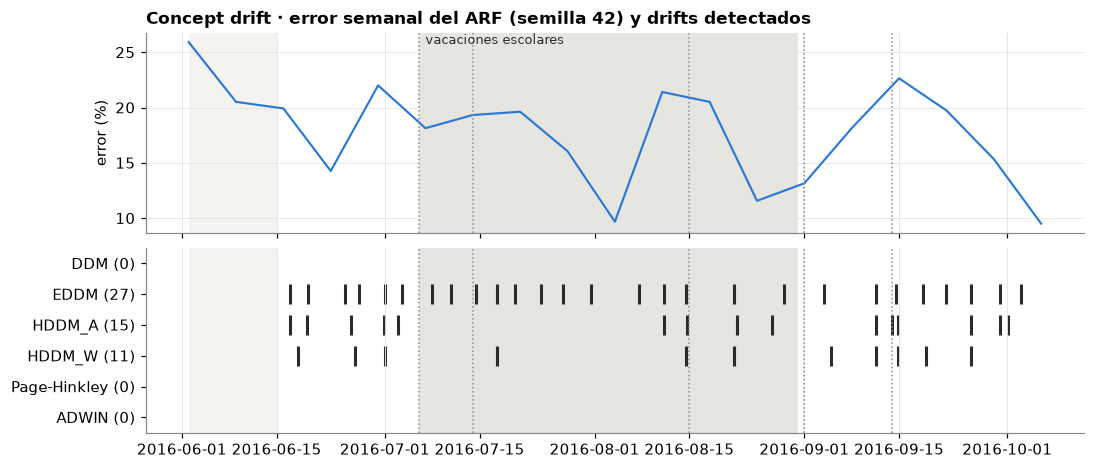

In [42]:
error_semanal = reg_arf["error"].resample("W-SUN").mean()
error_semanal.index = error_semanal.index - pd.Timedelta(days=3)
dibujar_detecciones(100 * error_semanal, {n: d for n, (w, d) in resultados_42.items()},
                    "Concept drift · error semanal del ARF (semilla 42) y drifts detectados", "error (%)", desde=INICIO_EVALUACION)

### ¿Son robustas estas detecciones? 10 semillas

Las detecciones dependen mucho de la ejecución: con otra semilla del ARF, u otro ordenador, salen otras fechas. Repetimos el análisis con las 10 ejecuciones de la sección 5.1 y medimos, para cada detector, cuántos drifts da y en qué porcentaje de ejecuciones salta cerca de cada evento del calendario.

In [43]:
FABRICAS = {"DDM": drift.binary.DDM, "EDDM": drift.binary.EDDM, "HDDM_A": drift.binary.HDDMA,
            "HDDM_W": drift.binary.HDDMW, "Page-Hinkley": lambda: drift.PageHinkley(mode="up"), "ADWIN": drift.ADWIN}
VENTANAS = {"inicio de vacaciones (6-20 jul)": ("2016-07-06", "2016-07-21"),
            "agosto (1-15 ago)": ("2016-08-01", "2016-08-16"),
            "vuelta a clase (29 ago-12 sep)": ("2016-08-29", "2016-09-13")}

filas = []
for s, reg in reg_semillas.items():
    errs = list(zip(reg["revelada"], reg["error"]))
    for nombre, fab in FABRICAS.items():
        avisos, drifts = vigilar(fab(), nombre, errs, imprimir=False)
        fila = {"semilla": s, "detector": nombre, "warnings": len(avisos), "drifts": len(drifts)}
        for v, (a, b) in VENTANAS.items():
            fila[v] = any(pd.Timestamp(a) <= d < pd.Timestamp(b) for d in drifts)
        filas.append(fila)
rob = pd.DataFrame(filas)

g = rob.groupby("detector", sort=False)
tabla_rob = pd.DataFrame({
    "drifts (media)": g["drifts"].mean(),
    "drifts (mín.-máx.)": g["drifts"].agg(lambda x: f"{x.min()}-{x.max()}"),
    "warnings (media)": g["warnings"].mean(),
    **{f"% ejecuciones con drift: {v}": 100 * g[v].mean() for v in VENTANAS},
}).round(1)
tabla_rob

,drifts (media),drifts (mín.-máx.),warnings (media),% ejecuciones con drift: inicio de vacaciones (6-20 jul),% ejecuciones con drift: agosto (1-15 ago),% ejecuciones con drift: vuelta a clase (29 ago-12 sep)
detector,,,,,,
DDM,2.3,0-7,15.1,20.0,0.0,0.0
EDDM,22.9,3-27,13.0,90.0,90.0,90.0
HDDM_A,10.5,5-16,26.8,80.0,80.0,70.0
HDDM_W,7.3,5-9,24.2,100.0,100.0,60.0
Page-Hinkley,0.0,0-0,0.0,0.0,0.0,0.0
ADWIN,0.7,0-1,0.0,0.0,10.0,60.0


### ¿Hay *concept drift* de verdad? Modelo congelado, 10 semillas

Las detecciones por sí solas no demuestran que haya *concept drift*. Experimento directo: un **modelo congelado** que aprende hasta el 1 de agosto y después deja de aprender (sigue prediciendo con lo aprendido en junio y julio). Si la relación entre las variables y la etiqueta cambia en agosto o en septiembre, **el modelo congelado empeorará** respecto al que sigue aprendiendo. Se repite con las 10 semillas (unos 90 segundos).

In [44]:
CONGELAR = pd.Timestamp("2016-08-01")
t0 = time.time()
reg_congelado_semillas = {s: prequential(forest.ARFClassifier(n_models=10, seed=s), flujo_bicis(), congelar_desde=CONGELAR)[0]
                          for s in SEMILLAS}
print(f"{time.time() - t0:.0f} s")

error_mes = lambda reg: 100 * reg["error"].groupby(reg.index.month).mean()
online = pd.DataFrame({s: error_mes(r) for s, r in reg_semillas.items()})
congelado = pd.DataFrame({s: error_mes(r) for s, r in reg_congelado_semillas.items()})
diferencia = congelado - online
comparacion = pd.DataFrame({
    "error online (%, media)": online.mean(axis=1),
    "error congelado (%, media)": congelado.mean(axis=1),
    "diferencia (puntos, media)": diferencia.mean(axis=1),
    "diferencia (desv. típica)": diferencia.std(axis=1),
    "semillas en que el congelado es peor": (diferencia > 0).sum(axis=1).astype(str) + f" de {len(SEMILLAS)}",
}).round(1)
comparacion.index = ["jun", "jul", "ago", "sep", "oct"][:len(comparacion)]
comparacion

129 s


,"error online (%, media)","error congelado (%, media)","diferencia (puntos, media)",diferencia (desv. típica),semillas en que el congelado es peor
jun,20.3,20.3,0.0,0.0,0 de 10
jul,19.1,19.1,0.0,0.0,0 de 10
ago,15.1,16.3,1.2,0.6,9 de 10
sep,16.4,16.6,0.3,0.8,6 de 10
oct,12.9,13.1,0.2,3.1,7 de 10


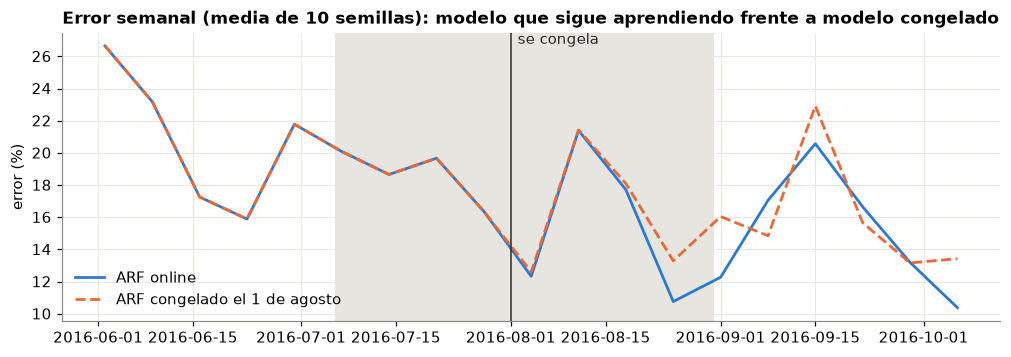

In [45]:
def error_semanal_medio(registros):
    semanas = pd.DataFrame({s: r["error"].resample("W-SUN").mean() for s, r in registros.items()})
    semanas.index = semanas.index - pd.Timedelta(days=3)
    return 100 * semanas.mean(axis=1)

fig, ax = plt.subplots(figsize=(11, 3.4))
for regs, nombre, color, ls in [(reg_semillas, "ARF online", AZUL, "-"),
                                (reg_congelado_semillas, "ARF congelado el 1 de agosto", NARANJA, "--")]:
    e = error_semanal_medio(regs)
    ax.plot(e.index, e.values, color=color, ls=ls, lw=1.8, label=nombre)
ax.axvline(CONGELAR, color=TINTA, lw=1)
ax.text(CONGELAR + pd.Timedelta(days=1), ax.get_ylim()[1], "se congela", va="top", color=TINTA)
ax.axvspan(*VACACIONES, color=SOMBRA, lw=0, zorder=0)
ax.set_title("Error semanal (media de 10 semillas): modelo que sigue aprendiendo frente a modelo congelado")
ax.set_ylabel("error (%)")
ax.legend(frameon=False, loc="lower left")
plt.show()

**Conclusión (H2): solo hay un *concept drift* muy leve, en agosto, y ningún detector lo detecta de forma fiable.**

- **Modelo congelado:** en agosto falla 1,2 puntos más que el online, y eso pasa **en las 10 semillas**: con las vacaciones cambia un poco la relación entre las variables y la etiqueta. En septiembre la diferencia es de solo 0,2 puntos (el congelado es peor en 6 de 10 semillas), así que **no hay evidencia de *concept drift* con la vuelta a clase**. El ARF online absorbe el cambio en todos los casos.
- **DDM y Page-Hinkley** prácticamente no saltan (DDM da 1,5 drifts de media, casi todos en el aprendizaje inicial; Page-Hinkley ninguno): con un cambio tan pequeño no acumulan evidencia suficiente.
- **EDDM (23 drifts de media), HDDM_A (11) y HDDM_W (8) saltan cada pocos días**, igual que sus zonas de *warning* (15-27 por ejecución). Por eso aparecen "cerca" de cualquier evento en el 70-100 % de las ejecuciones: no es que detecten los eventos, es que saltan continuamente. Son falsas alarmas.
- **ADWIN** da 0 o 1 drift por ejecución. Cuando salta, en 4 de cada 10 ejecuciones lo hace en la vuelta a clase, un cambio que el modelo congelado no confirma, y nunca detecta el de agosto, que es el único confirmado.
- **La ejecución de ejemplo (semilla 42) es engañosa:** en ella ADWIN salta el 2 de septiembre y parece detectar la vuelta a clase, pero eso solo ocurre en 4 de 10 semillas. **Con una sola ejecución se pueden sacar conclusiones erróneas sobre los detectores.**
- **Para qué sirve aquí:** en este flujo basta con el aprendizaje online (el ARF ya lleva un ADWIN dentro de cada árbol). Un detector externo que dispare reentrenamientos no aporta y, con EDDM o HDDM, provocaría reentrenamientos innecesarios. Para evaluar los detectores y las estrategias de adaptación hace falta un drift claro y conocido: notebook 3.

## 5.3 *Data drift*: ¿cambian los datos que llegan?

**Para qué:** los detectores de *data drift* vigilan las variables de entrada **sin necesitar etiquetas**, así que pueden avisar antes que los de *concept drift* (que esperan 2 horas a la etiqueta) y señalan **qué variable** ha cambiado. Su limitación: no dicen si el cambio afecta al modelo.

Detectores del tema para una variable numérica:
- **ADWIN**: ventana adaptativa; detecta cambios en la **media**.
- **KSWIN**: test de Kolmogorov-Smirnov entre una ventana reciente y otra de referencia; detecta cambios en la **distribución** completa.
- **Page-Hinkley**: suma acumulada de desviaciones respecto a la media; detecta cambios de **media** rápido, pero su umbral depende de la escala de la variable.

### Desestacionalización online

El exploratorio mostró un ciclo diario y semanal muy marcado (H3). Para no confundirlo con un cambio real, a cada valor le restamos la **media de su misma franja horaria y tipo de día** (laborable o fin de semana/festivo), calculada **solo con los datos que ya han llegado** (`river.stats.Mean` por franja). El resultado es una **anomalía**: cuánto se aparta el valor de lo normal para ese momento.

Todo se calcula en **una sola pasada** por el flujo.

In [46]:
MIN_OBS = 4      # observaciones de una franja antes de empezar a calcular su anomalía

medias = collections.defaultdict(stats.Mean)
filas = []
for x, y in flujo_bicis():
    t = x["momento"]
    tipo = "finde" if x["es_finde"] or x["es_festivo"] else "laborable"
    franja = (t.hour * 2 + t.minute // 30, tipo)
    fila = {"momento": t, "temperatura": x["temperatura"]}
    for var in ["bicis", "movimientos_30min"]:
        m = medias[(var, franja)]
        fila[var] = x[var]
        fila[f"{var}_anomalia"] = x[var] - m.get() if m.n >= MIN_OBS else np.nan
        m.update(x[var])
    filas.append(fila)
senales = pd.DataFrame(filas).set_index("momento")

print("Desviación típica y autocorrelación a 30 min:")
pd.DataFrame({c: {"desv. típica": senales[c].std(), "autocorrelación (30 min)": senales[c].autocorr(1)}
              for c in ["bicis", "bicis_anomalia", "movimientos_30min", "movimientos_30min_anomalia"]}).round(2).T

Desviación típica y autocorrelación a 30 min:


,desv. típica,autocorrelación (30 min)
bicis,6.38,0.91
bicis_anomalia,4.13,0.81
movimientos_30min,4.14,0.64
movimientos_30min_anomalia,2.80,0.24


In [47]:
def ejecutar(detector, serie):
    """Pasa una serie por un detector y devuelve las fechas en que detecta drift."""
    fechas = []
    for t, v in serie.dropna().items():
        detector.update(float(v))
        if detector.drift_detected:
            fechas.append(t)
    return fechas


def detectores_datos():
    return {"ADWIN": drift.ADWIN(), "KSWIN": drift.KSWIN(seed=42), "Page-Hinkley": drift.PageHinkley()}

### H3: ¿salta el detector con el ciclo diario?

Aplicamos los tres detectores, con sus parámetros por defecto, a las señales de 30 minutos: tal cual y desestacionalizadas.

In [48]:
meses = (senales.index.max() - senales.index.min()).days / 30.4
filas = {}
for col, etiqueta in [("bicis", "bicis tal cual"), ("bicis_anomalia", "bicis desestacionalizada"),
                      ("movimientos_30min", "uso tal cual"), ("movimientos_30min_anomalia", "uso desestacionalizado"),
                      ("temperatura", "temperatura tal cual")]:
    filas[etiqueta] = {nombre: round(len(ejecutar(det, senales[col])) / meses, 1) for nombre, det in detectores_datos().items()}
tabla_h3 = pd.DataFrame(filas).T
tabla_h3.columns = [f"{c} (alarmas/mes)" for c in tabla_h3.columns]
tabla_h3

,ADWIN (alarmas/mes),KSWIN (alarmas/mes),Page-Hinkley (alarmas/mes)
bicis tal cual,10.1,12.8,45.1
bicis desestacionalizada,8.9,11.6,30.4
uso tal cual,2.2,12.3,39.3
uso desestacionalizado,1.9,8.0,14.2
temperatura tal cual,11.8,13.5,40.3


**Conclusión (H3): confirmada.** Sobre las señales de 30 minutos tal cual, los detectores saltan continuamente: con las bicis, ADWIN da ~10 alarmas al mes, KSWIN ~13 y Page-Hinkley ~45, y con la temperatura pasa lo mismo. Lo que detectan es el **ciclo diario**, un drift recurrente y esperado, no un cambio real.

Desestacionalizar ayuda (en el uso, Page-Hinkley baja de 39 a 14 alarmas al mes y KSWIN de 12 a 8), pero no basta con las bicis, porque su anomalía sigue muy autocorrelacionada (0,81): un día con más o menos bicis de lo normal da 48 instancias seguidas por encima o por debajo, y ADWIN y KSWIN suponen observaciones independientes.

**Lección:** antes de vigilar una variable real hay que quitarle la estacionalidad y pensar a qué escala temporal ocurren los cambios que buscamos.

### H1 y H4: señales diarias

Con una instancia cada 30 minutos, la anomalía sigue muy autocorrelacionada (un día raro da 48 instancias raras seguidas). Los cambios que buscamos (vacaciones, vuelta a clase, bajada de temperatura) son de **días o semanas**, así que agregamos por día: al final de cada día llega al detector **un valor** (sigue siendo un flujo, ahora diario).
- **H1:** anomalía media diaria del **uso** (`movimientos_30min` desestacionalizado).
- **H4:** **temperatura media diaria** (la media diaria también elimina los picos falsos de temperatura del notebook 1).

Solo se usan los días completos (al menos 44 de las 48 medias horas).

In [49]:
completos = senales["bicis"].resample("D").count() >= 44
diarias = pd.DataFrame({
    "uso_anomalia": senales["movimientos_30min_anomalia"].resample("D").mean(),
    "temperatura": senales["temperatura"].resample("D").mean(),
})[completos].dropna()
print(f"Días: {len(diarias)}")
print("Anomalía media del uso por mes (movimientos por 30 min respecto a lo normal para la franja):")
print(diarias["uso_anomalia"].groupby(diarias.index.month).mean().round(2).rename({6: "jun", 7: "jul", 8: "ago", 9: "sep", 10: "oct"}).to_dict())

filas = {}
for col, etiqueta in [("uso_anomalia", "H1 · uso (anomalía diaria)"), ("temperatura", "H4 · temperatura media diaria")]:
    for nombre, det in {"ADWIN": drift.ADWIN(), "KSWIN": drift.KSWIN(seed=42),
                        "KSWIN (ventana 30, reciente 7)": drift.KSWIN(window_size=30, stat_size=7, seed=42),
                        "Page-Hinkley": drift.PageHinkley()}.items():
        filas[(etiqueta, nombre)] = ", ".join(d.strftime("%d-%m") for d in ejecutar(det, diarias[col])) or "—"
pd.Series(filas, name="fechas de detección").to_frame()

Días: 115
Anomalía media del uso por mes (movimientos por 30 min respecto a lo normal para la franja):
{'jun': 0.56, 'jul': -0.3, 'ago': -0.57, 'sep': 0.34, 'oct': 0.43}


fechas de detección
H1 · uso (anomalía diaria)    ADWIN                                            —
                              KSWIN                                        26-09
                              KSWIN (ventana 30, reciente 7)               05-09
                              Page-Hinkley                                     —
H4 · temperatura media diaria ADWIN                                            —
                              KSWIN                                            —
                              KSWIN (ventana 30, reciente 7)        10-07, 23-09
                              Page-Hinkley                          14-08, 26-09

**Conclusión.** Con los parámetros por defecto, los detectores casi no ven nada en las señales diarias. ADWIN y Page-Hinkley no detectan ningún cambio en el uso, aunque la anomalía media pasa de +0,56 en junio a −0,57 en agosto y vuelve a +0,34 en septiembre. Solo KSWIN con una ventana más corta (30 días, 7 recientes) detecta la **vuelta a clase (5 de septiembre)** en el uso y la **bajada de temperatura (23 de septiembre)**.

Los parámetros por defecto no encajan con un flujo de ~115 instancias: se ajustan en la sección 5.4.

### H4: ¿afecta la bajada de temperatura al modelo?

Comparamos el error del ARF (media de las 10 semillas) en las dos semanas antes y después del 14 de septiembre. Como la bajada de temperatura coincide en el tiempo con la vuelta a la universidad, añadimos un control: el **modelo congelado sin las variables de temperatura y humedad**. Si empeora igual, el empeoramiento no se debe a la temperatura.

In [50]:
class SinVariables:
    """Envuelve un modelo y le oculta algunas variables."""
    def __init__(self, modelo, quitar):
        self.modelo, self.quitar = modelo, set(quitar)
    def predict_one(self, x):
        return self.modelo.predict_one({k: v for k, v in x.items() if k not in self.quitar})
    def learn_one(self, x, y):
        self.modelo.learn_one({k: v for k, v in x.items() if k not in self.quitar}, y)


t0 = time.time()
reg_congelado_sin_meteo = {s: prequential(SinVariables(forest.ARFClassifier(n_models=10, seed=s), ["temperatura", "humedad"]),
                                          flujo_bicis(), congelar_desde=CONGELAR)[0] for s in SEMILLAS}
print(f"{time.time() - t0:.0f} s")

CAMBIO_T = EVENTOS["14 sep: baja la temperatura"]
antes = slice(CAMBIO_T - pd.Timedelta(days=14), CAMBIO_T)
despues = slice(CAMBIO_T, CAMBIO_T + pd.Timedelta(days=14))


def error_periodos(registros):
    """Error medio (10 semillas) antes y después del 14 de septiembre, y cuántas semillas empeoran."""
    a = pd.Series({s: 100 * r["error"][antes].mean() for s, r in registros.items()})
    d = pd.Series({s: 100 * r["error"][despues].mean() for s, r in registros.items()})
    return [f"{a.mean():.1f}", f"{d.mean():.1f}", f"{(d - a).mean():+.1f} ({(d > a).sum()} de {len(a)} semillas empeoran)"]


pd.DataFrame({
    "temperatura media (°C)": [f"{senales['temperatura'][antes].mean():.1f}", f"{senales['temperatura'][despues].mean():.1f}",
                               f"{senales['temperatura'][despues].mean() - senales['temperatura'][antes].mean():+.1f}"],
    "error ARF online (%)": error_periodos(reg_semillas),
    "error ARF congelado (%)": error_periodos(reg_congelado_semillas),
    "error congelado sin temperatura ni humedad (%)": error_periodos(reg_congelado_sin_meteo),
}, index=["2 semanas antes del 14 sep", "2 semanas después", "cambio"])

22 s


,temperatura media (°C),error ARF online (%),error ARF congelado (%),error congelado sin temperatura ni humedad (%)
2 semanas antes del 14 sep,24.3,15.6,15.7,15.3
2 semanas después,18.6,17.3,17.9,18.4
cambio,-5.8,+1.8 (8 de 10 semillas empeoran),+2.2 (10 de 10 semillas empeoran),+3.0 (10 de 10 semillas empeoran)


**Conclusión (H4): la bajada de temperatura es *data drift* que no explica el error del modelo.** La temperatura media baja 5,8 °C (de 24,3 a 18,6 °C) y KSWIN lo detecta (23 de septiembre).

En las dos semanas siguientes el error sube un poco en todos los modelos: +1,3 puntos el ARF online (en 9 de 10 semillas), +2,3 el congelado y **+2,6 el congelado sin temperatura ni humedad** (en las 10 semillas). Si la temperatura fuera la causa, el modelo que no la ve no empeoraría; empeora igual o más. El empeoramiento se debe a otros cambios de esas semanas (por ejemplo, la vuelta a la universidad), no a la temperatura.

Una alarma de *data drift* **no obliga a reentrenar**: sirve para registrar el cambio y comprobar, con el error, si afecta al modelo.

## 5.4 Ajuste de parámetros

Con los parámetros por defecto, los detectores apenas ven el cambio de uso de H1. No es que los detectores fallen: los parámetros por defecto están pensados para flujos largos y cambios claros, y aquí tenemos **pocas instancias** (unos 120 días) y una **distribución muy parecida entre meses** (la anomalía media cambia menos de 1 movimiento por media hora, con una desviación típica diaria de ~1). Ajustamos cada detector **justificando cada cambio**:

| Detector | Parámetro | Por defecto | Qué controla |
|---|---|---|---|
| ADWIN | `delta` | 0,002 | confianza del test: **más alto = más sensible** (más detecciones, más falsas alarmas) |
| ADWIN | `clock` | 32 | cada cuántas instancias comprueba si hay cambio: con 120 días, 32 es casi una comprobación al mes |
| ADWIN | `grace_period` | 10 | instancias antes de empezar a detectar |
| KSWIN | `window_size` / `stat_size` | 100 / 30 | tamaño de la ventana total y de la parte reciente: 100 días es casi todo el flujo |
| KSWIN | `alpha` | 0,005 | nivel de significación del test |
| Page-Hinkley | `threshold` | 50 | umbral en **unidades de la variable**: 50 es enorme para una anomalía con desviación típica ~1 |
| Page-Hinkley | `mode` | `"both"` | detectar subidas, bajadas o ambas |

In [51]:
serie_h1 = diarias["uso_anomalia"]
sd = serie_h1.std()
print(f"Desviación típica de la anomalía diaria de uso: {sd:.2f}")

configuraciones = {}
for d in [0.002, 0.01, 0.05, 0.1, 0.2, 0.5]:
    configuraciones[("ADWIN", f"delta={d}, clock=1, grace_period=7")] = drift.ADWIN(delta=d, clock=1, grace_period=7, min_window_length=5)
for a in [0.005, 0.05]:
    for w, s in [(30, 7), (28, 14), (42, 14)]:
        configuraciones[("KSWIN", f"alpha={a}, window_size={w}, stat_size={s}")] = drift.KSWIN(alpha=a, window_size=w, stat_size=s, seed=42)
for k in [2, 4, 6]:
    for modo in ["both", "up", "down"]:
        configuraciones[("Page-Hinkley", f"threshold={k}·sd, mode={modo}")] = drift.PageHinkley(threshold=k * sd, min_instances=7, mode=modo)

barrido = {clave: ejecutar(det, serie_h1) for clave, det in configuraciones.items()}
pd.DataFrame({"detecciones": {k: len(v) for k, v in barrido.items()},
              "fechas": {k: ", ".join(d.strftime("%d-%m") for d in v) or "—" for k, v in barrido.items()}})

Desviación típica de la anomalía diaria de uso: 0.94


detecciones                                                                              fechas
ADWIN        delta=0.002, clock=1, grace_period=7                 0                                                                                   —
             delta=0.01, clock=1, grace_period=7                  0                                                                                   —
             delta=0.05, clock=1, grace_period=7                  1                                                                               11-08
             delta=0.1, clock=1, grace_period=7                   1                                                                               08-08
             delta=0.2, clock=1, grace_period=7                   2                                                                        03-08, 13-09
             delta=0.5, clock=1, grace_period=7                   2                                                                        22-07, 08-09
KSWIN        alpha=0.005, window_size=30, stat_size=7             1                                                                               05-09
             alpha=0.005, window_size=28, stat_size=14            2                                                                        20-07, 06-09
             alpha=0.005, window_size=42, stat_size=14            2                                                                        21-07, 07-09
             alpha=0.05, window_size=30, stat_size=7              2                                                                        17-07, 05-09
             alpha=0.05, window_size=28, stat_size=14             2                                                                        16-07, 31-08
             alpha=0.05, window_size=42, stat_size=14             2                                                                        20-07, 05-09
Page-Hinkley threshold=2·sd, mode=both                           12  15-06, 22-06, 29-06, 07-07, 14-07, 26-07, 04-08, 20-08, 27-08, 03-09, 10-09, 22-09
             threshold=2·sd, mode=up                              5                                                   22-06, 27-08, 03-09, 10-09, 22-09
             threshold=2·sd, mode=down                            4                                                          15-06, 04-07, 11-07, 09-08
             threshold=4·sd, mode=both                            6                                            19-06, 03-07, 14-07, 30-07, 27-08, 03-09
             threshold=4·sd, mode=up                              2                                                                        24-06, 31-08
             threshold=4·sd, mode=down                            4                                                          19-06, 03-07, 14-07, 15-08
             threshold=6·sd, mode=both                            4                                                          19-06, 07-07, 17-07, 01-09
             threshold=6·sd, mode=up                              1                                                                               05-09
             threshold=6·sd, mode=down                            3                                                                 19-06, 07-07, 17-07

**Lectura del barrido:**
- **ADWIN:** con `delta` ≤ 0,01 no detecta nada: los cambios entre meses son pequeños para la confianza que exige. Con `delta=0,2` detecta dos cambios: el **3 de agosto** (bajada del uso en vacaciones) y el **13 de septiembre** (recuperación tras la vuelta a clase). Con `delta=0,5` adelanta las fechas (22 de julio y 8 de septiembre), pero un `delta` tan alto daría más falsas alarmas en otros periodos. Elegimos **`delta=0,2`**, el valor más exigente que detecta los dos cambios. Además, `clock=1` (comprobar cada día) es necesario: con el valor por defecto (32) solo comprobaría unas 4 veces en todo el periodo.
- **KSWIN:** es el más **robusto**: con todas las combinaciones probadas detecta dos cambios, uno **a mediados de julio** y otro **en los primeros días de septiembre**. Elegimos `window_size=28, stat_size=14` (compara las 2 últimas semanas con las anteriores), que tiene sentido para cambios de comportamiento que duran semanas, y dejamos `alpha=0,005` por defecto.
- **Page-Hinkley:** con un umbral bajo (2·sd, en las dos direcciones) salta 12 veces, casi una por semana. Con 4·sd y separando la dirección, **`mode="up"` detecta la recuperación del 31 de agosto** (un día antes de la vuelta a clase), y **`mode="down"` salta en los festivos del 14 de julio y el 15 de agosto** y al inicio de julio: reacciona a días sueltos con mucho menos uso, que no son un cambio de comportamiento.

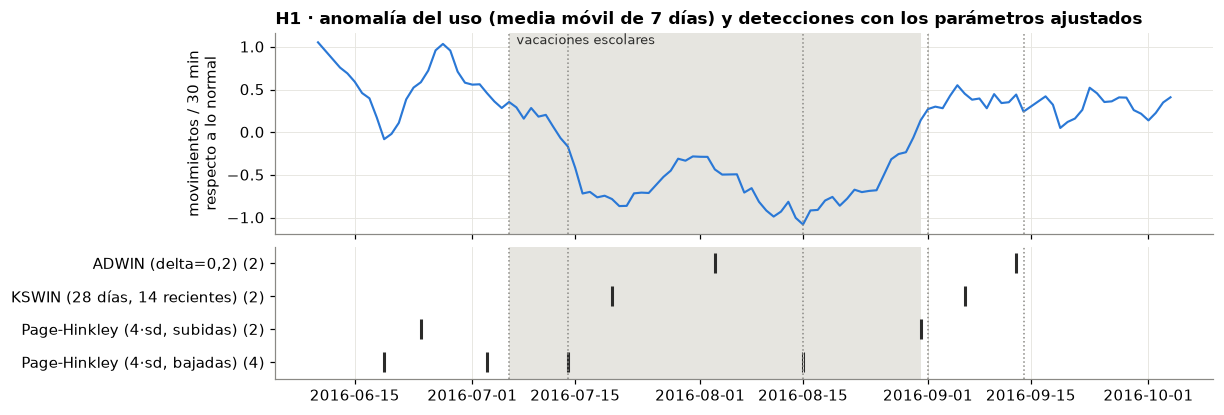

In [52]:
ELEGIDOS = {
    "ADWIN (delta=0,2)": ("ADWIN", "delta=0.2, clock=1, grace_period=7"),
    "KSWIN (28 días, 14 recientes)": ("KSWIN", "alpha=0.005, window_size=28, stat_size=14"),
    "Page-Hinkley (4·sd, subidas)": ("Page-Hinkley", "threshold=4·sd, mode=up"),
    "Page-Hinkley (4·sd, bajadas)": ("Page-Hinkley", "threshold=4·sd, mode=down"),
}
media_semanal = serie_h1.rolling(7, min_periods=4).mean()
dibujar_detecciones(media_semanal, {n: barrido[c] for n, c in ELEGIDOS.items()},
                    "H1 · anomalía del uso (media móvil de 7 días) y detecciones con los parámetros ajustados",
                    "movimientos / 30 min\nrespecto a lo normal")

**Conclusión (H1): confirmada.** La anomalía del uso baja a partir de mediados de julio (los colegios cierran el 6 de julio y el uso cae en las semanas siguientes), se mantiene baja en agosto y se recupera en los últimos días de agosto, justo antes de la vuelta a clase.

Con los parámetros ajustados:
- **KSWIN detecta los dos cambios en los momentos correctos** (20 de julio y 6 de septiembre);
- ADWIN los detecta con más retraso (3 de agosto y 13 de septiembre);
- Page-Hinkley detecta la recuperación (31 de agosto), pero confunde los festivos con cambios.

Para este flujo, **KSWIN sobre la anomalía diaria del uso** es el mejor detector de *data drift*. Detecta el cambio de comportamiento **sin necesitar etiquetas**, incluso cuando no afecta al modelo: en julio y agosto el uso baja, pero el error del ARF no sube.

**Limitación (para el análisis crítico):** los parámetros se han ajustado mirando el mismo periodo en el que se evalúan, conociendo ya las fechas de las vacaciones. En un sistema real habría que fijarlos con un periodo anterior (por ejemplo, el verano de otro año) y comprobar después que funcionan. Por otra parte, los resultados que dependen del modelo (sección 5.2 y la parte del error de H4) se han repetido con 10 semillas, porque una sola ejecución puede llevar a conclusiones erróneas. Los de *data drift* no dependen del modelo y son siempre iguales.

## Resumen de las hipótesis

| | Hipótesis | Resultado | Evidencia |
|---|---|---|---|
| **H1** | *Data drift* en el uso con las vacaciones y la vuelta a clase | **Confirmada** | La anomalía del uso pasa de +0,56 (junio) a −0,57 (agosto) y vuelve a +0,34 (septiembre). KSWIN (28/14 días) lo detecta el 20 de julio y el 6 de septiembre, pero **solo con los parámetros ajustados** |
| **H2** | *Concept drift* en septiembre | **No se confirma** (solo un efecto muy leve en agosto) | El congelado falla 1,2 puntos más en agosto (10 de 10 semillas) y solo 0,2 en septiembre (6 de 10). Ningún detector lo detecta de forma fiable; el ARF online lo absorbe |
| **H3** | El ciclo diario y semanal no debería disparar alarmas | **Confirmada** (es un problema real) | Sobre las señales de 30 minutos tal cual, entre 10 y 45 alarmas al mes. Hay que desestacionalizar y agregar por día |
| **H4** | La bajada de temperatura es *data drift* sin efecto en el modelo | **Confirmada** | KSWIN la detecta el 23 de septiembre. El error sube algo después, pero igual o más en el modelo que no ve la temperatura |

**Qué falta (notebook 3):** en este flujo el *concept drift* es pequeño y el ARF se adapta solo, así que no podemos comparar **estrategias de adaptación** (reiniciar el modelo, modelo en segundo plano, árboles adaptativos…) ni medir el **retardo** de cada detector con un cambio conocido. Para eso, el notebook 3 simula un *concept drift* fuerte con datos reales: el sistema entrenado con *pomme* empieza a recibir, en una fecha conocida, los datos de otra estación (*place-jeanne-darc*), como si se desplegara en otro punto de la ciudad.